# PRIDE API Tutorial

This Jupyter Notebook will walk you through how to find proteomics datasets in the ProteomeXchange Consortium database. 

### Step 1: Importing Libraries 

To get started, we need to import the necessary libraries:
- `requests` to make HTTP requests to the API.
- `pprint` to display the results in a readable format.

In [22]:
import requests
import pprint

### Step 2: Setting up the API url and query parameters

We will use the Omics Discovery Index (OmicsDI) to search for datasets across all ProteomeXchange repositories (PRIDE, MassIVE, jPOST, iProX, etc.).

In [23]:
base_url = "https://www.omicsdi.org/ws/dataset/search"
species_name = "Trametes versicolor"

# OmicsDI allows a general query string.
# We filter by 'omics_type:Proteomics' to exclude non-proteomics data
params = {
    "query": f'"{species_name}" AND omics_type:"Proteomics"',
    "size": 100,  # Number of results to return --> increase this if you expect more
    "start": 0,
}


### Step 3: Making the GET request

Here, we use the 'requests.get' method to make the API request with the specified parameters. We also check if the request was successful.

In [24]:
datasets = None

try:
    response = requests.get(base_url, params=params)
    response.raise_for_status()
    data = response.json()

    datasets = data.get("datasets", [])

    if not datasets:
        print(f"No datasets found for {species_name}.")

    print(f"Found {data['count']} datasets across all repositories.\n")
    
except requests.exceptions.RequestException as e:
    print(f"Error connecting to OmicsDI: {e}")
    
pprint.pprint(datasets)

Found 8 datasets across all repositories.

[{'citationsCount': 0,
  'citationsCountScaled': 0.0,
  'claimable': False,
  'connectionsCount': 0,
  'connectionsCountScaled': 0.0,
  'description': 'A recent algicidal mode indicates that fungal mycelia can '
                 'wrap and eliminate almost all the co-cultivated algal cells '
                 'within a short time. However, the regulation of molecular '
                 'mechanism is rarely understood. Here, proteomic analysis was '
                 'applied to investigate the algicidal process of Trametes '
                 'versicolor F21a. Our results showed that 3,754 fungal '
                 'proteins were identified, among which 2,809 unique proteins '
                 'could be quantified during the process. 30 isoenzymes with '
                 'the capacity of degradation biomass, belonging to Glycoside '
                 'Hydrolases, Auxiliary Activities, Carbohydrate Esterases and '
                 'Polysaccharide Ly

### Step 4: Parsing the datasets and extracting relevant information


In [25]:
results_list = []

print(f"{'ID':<15} | {'Repository':<10} | {'Title':<52} | {'Year'} | {'Species'}")
print("-" * 130)

for ds in datasets:
    # OmicsDI returns the source DB (e.g., 'pride', 'massive') and the ID
    accession = ds["id"]
    database = ds["source"]
    title = ds["title"]
    species = ds["organisms"]
    date = ds["publicationDate"]

    results_list.append((accession, database))

    # Truncate title for cleaner printing
    short_title = (title[:50] + "..") if len(title) > 50 else title

    # Extract year from publication date
    year = date[:4] if date else "N/A"

    # Extract species name(s) as a comma-separated string
    if isinstance(species, list) and species and "name" in species[0]:
        species_str = ", ".join([org["name"] for org in species if "name" in org])
    else:
        species_str = str(species)

    print(f"{accession:<15} | {database:<10} | {short_title:<52} | {year} | {species_str}")

# Count datasets per source
import collections
source_counts = collections.Counter([db for _, db in results_list])
print("\nDatasets per source:")
for source, count in source_counts.items():
    print(f"{source}: {count}")

ID              | Repository | Title                                                | Year | Species
----------------------------------------------------------------------------------------------------------------------------------
PXD005568       | pride      | Proteomic analysis reveals large amounts of decomp.. | 2018 | Trametes versicolor
PXD019839       | pride      | Intracellular pathways for lignin catabolism in wh.. | 2021 | Trametes versicolor, Ceriporiopsis subvermispora
MSV000095519    | massive    | Metabolic characterization of two white-rot fungi .. | 2024 | Gelatoporia Subvermispora (ncbitaxon:42742), Trametes Versicolor (ncbitaxon:5325)
MSV000085635    | massive    | A secretome tailored to endure early oxidative str.. | 2020 | Trichoderma Reesei (ncbitaxon:51453), Postia Placenta (ncbitaxon:104341), Trametes Versicolor (ncbitaxon:5325)
PXD036889       | pride      | Wood degradation by Fomitiporia mediterranea M. Fi.. | 2022 | Fomitiporia mediterranea
MSV000094781    

In [ ]:
import csv

# Save the dataset summary to a CSV file
with open("trametes_datasets_summary.csv", "w", newline='', encoding='utf-8') as csvfile:
    writer = csv.writer(csvfile)
    writer.writerow(["ID", "Repository", "Title", "Year", "Species"])
    for ds in datasets:
        accession = ds["id"]
        database = ds["source"]
        title = ds["title"]
        date = ds["publicationDate"]
        species = ds["organisms"]
        # Extract species name(s) as a comma-separated string
        if isinstance(species, list) and species and "name" in species[0]:
            species_str = ", ".join([org["name"] for org in species if "name" in org])
        else:
            species_str = str(species)
        # Extract year from publication date
        year = date[:4] if date else "N/A"
        writer.writerow([accession, database, title, year, species_str])

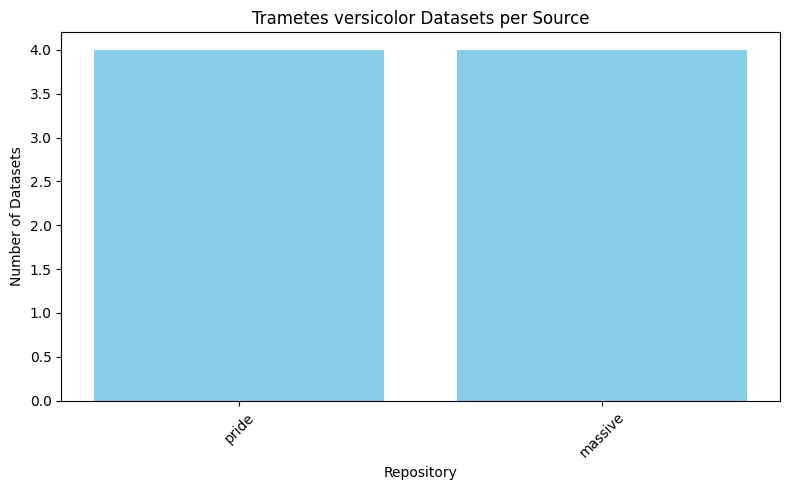

In [ ]:
import matplotlib.pyplot as plt

# Plotting the dataset counts per source
sources = list(source_counts.keys())
counts = list(source_counts.values())

plt.figure(figsize=(8, 5))
plt.bar(sources, counts, color='skyblue')
plt.xlabel('Repository')
plt.ylabel('Number of Datasets')
plt.title('Trametes versicolor Datasets per Source')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("trametes_datasets_count.jpg", dpi=300)  # Save the figure as a .jpg file
plt.show()